# Is NM–movement coupling an individual trait?

Separate project (not the individuality paper). Coupling = how strongly each fiber's photometry tracks movement, per session, from the caches of `run_nm_syllable_effects.py`. Functions in `coupling_individuality.py`.

1. **Coupling per fiber-session**: partial β (task covariates held fixed, outcomes averaged) of still paw, whisking and licking; unique CV R² of all vigor and of whisker ME beyond the task variables. Each in three epochs (pre-stimulus −0.5–0 s, post-stimulus 0–0.5 s, post-feedback 0–1 s).
2. **Trait-ness** per NM (mice with ≥ 4 sessions): ICC(1), the between-mouse share of the session-to-session variance; split-half reliability of mouse means (Spearman-Brown); null = session labels shuffled across mice (1000×).
3. **Confounds**: recording day (drift with training stage) and signal quality (session-level task-variable R² after feedback).
4. **Fiber vs mouse**: mice with two fibers recorded in the same sessions separate the animal from the implant.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators'))
from Functions import nm_syllables as ns
import coupling_individuality as ci
warnings.filterwarnings('ignore')

TAB = ci.add_task_r2(ci.coupling_table())
REC = ns.load_recordings()[['eid', 'brain_region', 'hemisphere']].rename(columns={'brain_region': 'region'})
TAB = TAB.merge(REC, on=['eid', 'region'], how='left')
METRICS = [c for c in TAB if c.startswith(('β', 'R² vigor', 'R² whisker'))]
TAB.groupby('target_NM').agg(fibers=('eid', 'size'), mice=('subject', 'nunique'),
                             mice_4plus=('subject', lambda s: (s.value_counts() >= ci.MIN_SESSIONS).sum())).loc[ci.NM_ORDER]

,fibers,mice,mice_4plus
target_NM,,,
DR-5HT,140,9,8
VTA-DA,140,7,5
SNc-DA,65,6,5
LC-NE,96,8,4
NBM-ACh,75,7,5


## 1–3. How stable is coupling within a mouse?

ICC per NM and metric, raw, after removing a common recording-day trend, and after partialling the signal-quality proxy. Bold outline: permutation p < .01.

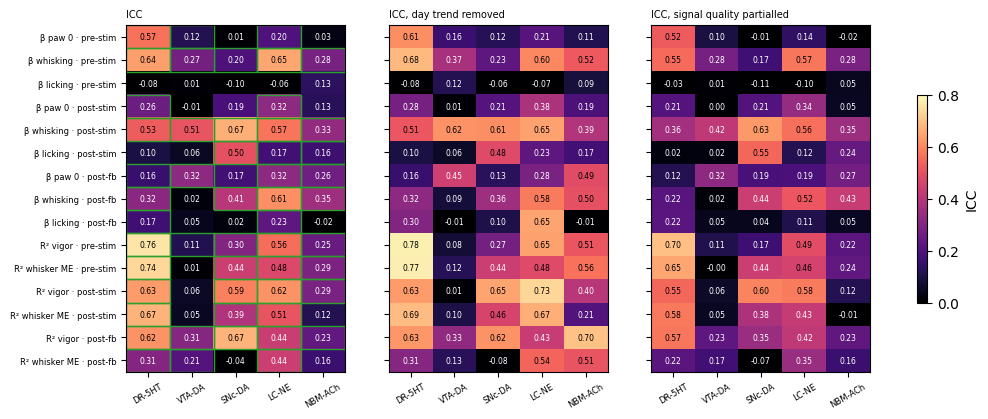

mice with >= 4 sessions: {'DR-5HT': 8, 'LC-NE': 4, 'NBM-ACh': 5, 'SNc-DA': 5, 'VTA-DA': 6}


mice  sessions    ICC  p (perm)  \
NM      metric                                                       
DR-5HT  β paw 0 · pre-stim            8       137  0.565     0.001   
        β whisking · pre-stim         8       137  0.638     0.001   
        β licking · pre-stim          8       137 -0.083     0.769   
        β paw 0 · post-stim           8       137  0.258     0.001   
        β whisking · post-stim        8       137  0.528     0.001   
...                                 ...       ...    ...       ...   
NBM-ACh R² whisker ME · pre-stim      5        71  0.289     0.001   
        R² vigor · post-stim          5        71  0.287     0.002   
        R² whisker ME · post-stim     5        71  0.116     0.025   
        R² vigor · post-fb            5        71  0.235     0.002   
        R² whisker ME · post-fb       5        71  0.162     0.016   

                                   split-half  ICC, day trend removed  \
NM      metric                                                          
DR-5HT  β paw 0 · pre-stim              0.879                   0.611   
        β whisking · pre-stim           0.889                   0.681   
        β licking · pre-stim              NaN                  -0.076   
        β paw 0 · post-stim             0.744                   0.278   
        β whisking · post-stim          0.863                   0.513   
...                                       ...                     ...   
NBM-ACh R² whisker ME · pre-stim        0.857                   0.563   
        R² vigor · post-stim            0.850                   0.405   
        R² whisker ME · post-stim       0.764                   0.208   
        R² vigor · post-fb              0.932                   0.697   
        R² whisker ME · post-fb         0.797                   0.508   

                                   ICC, signal quality partialled  \
NM      metric                                                      
DR-5HT  β paw 0 · pre-stim                                  0.524   
        β whisking · pre-stim                               0.551   
        β licking · pre-stim                               -0.026   
        β paw 0 · post-stim                                 0.211   
        β whisking · post-stim                              0.363   
...                                                           ...   
NBM-ACh R² whisker ME · pre-stim                            0.236   
        R² vigor · post-stim                                0.116   
        R² whisker ME · post-stim                          -0.012   
        R² vigor · post-fb                                  0.233   
        R² whisker ME · post-fb                             0.160   

                                   within-mouse r with day  p day  
NM      metric                                                     
DR-5HT  β paw 0 · pre-stim                           0.135  0.415  
        β whisking · pre-stim                       -0.144  0.388  
        β licking · pre-stim                         0.128  0.318  
        β paw 0 · post-stim                          0.160  0.502  
        β whisking · post-stim                      -0.057  0.707  
...                                                    ...    ...  
NBM-ACh R² whisker ME · pre-stim                    -0.151  0.415  
        R² vigor · post-stim                        -0.216  0.388  
        R² whisker ME · post-stim                   -0.193  0.291  
        R² vigor · post-fb                          -0.101  0.623  
        R² whisker ME · post-fb                     -0.018  0.925  

[75 rows x 9 columns]

In [2]:
raw = ci.trait_stats(TAB, METRICS)
day = ci.trait_stats(TAB, METRICS, detrend_day=True)[['NM', 'metric', 'ICC']].rename(columns={'ICC': 'ICC, day trend removed'})
snr = ci.trait_stats(ci.partial_out(TAB, METRICS, 'R² task · post-fb'), METRICS)[['NM', 'metric', 'ICC']].rename(
    columns={'ICC': 'ICC, signal quality partialled'})
drift = ci.day_drift(TAB, METRICS).rename(columns={'r with day': 'within-mouse r with day', 'p': 'p day'})
STATS = raw.merge(day, on=['NM', 'metric']).merge(snr, on=['NM', 'metric']).merge(drift, on=['NM', 'metric'])

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, col in zip(axes, ['ICC', 'ICC, day trend removed', 'ICC, signal quality partialled']):
    M = STATS.pivot(index='metric', columns='NM', values=col).loc[METRICS, ci.NM_ORDER]
    P = STATS.pivot(index='metric', columns='NM', values='p (perm)').loc[METRICS, ci.NM_ORDER]
    im = ax.imshow(M.to_numpy(), cmap='magma', vmin=0, vmax=0.8, aspect='auto')
    for (i, j), v in np.ndenumerate(M.to_numpy()):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=5.5, color='w' if v < 0.45 else 'k')
        if col == 'ICC' and P.iat[i, j] < 0.01:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec='C2', lw=1))
    ax.set_xticks(range(len(ci.NM_ORDER)), ci.NM_ORDER, fontsize=6, rotation=30)
    ax.set_yticks(range(len(METRICS)), METRICS, fontsize=6); ax.set_title(col, fontsize=7, loc='left')
fig.colorbar(im, ax=axes, shrink=0.6, label='ICC')
plt.show()
mice = TAB[TAB.groupby('subject')['eid'].transform('size') >= ci.MIN_SESSIONS].groupby('target_NM')['subject'].nunique()
print('mice with >= 4 sessions:', mice.to_dict())
STATS.set_index(['NM', 'metric']).round(3)

### Each fiber's sessions

One column per fiber (mouse · region), dots = sessions, bar = mean. If coupling is a trait, fibers separate cleanly; the spread within a column is session noise.

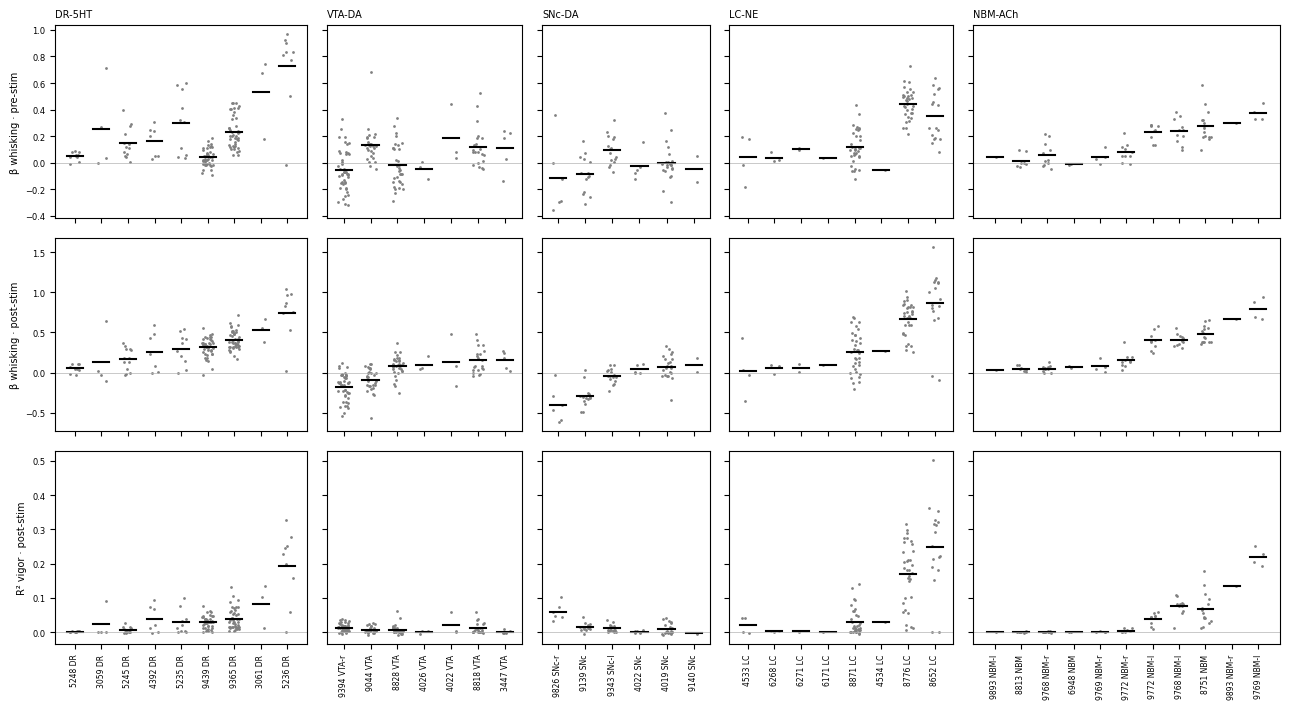

In [3]:
SHOW = ['β whisking · pre-stim', 'β whisking · post-stim', 'R² vigor · post-stim']
fig, axes = plt.subplots(len(SHOW), len(ci.NM_ORDER), figsize=(13, 2.4 * len(SHOW)), sharey='row',
                         gridspec_kw={'width_ratios': [TAB[TAB.target_NM == nm].groupby(['subject', 'region']).ngroups
                                                       for nm in ci.NM_ORDER]})
for j, nm in enumerate(ci.NM_ORDER):
    g = TAB[TAB.target_NM == nm]
    fibers = g.groupby(['subject', 'region'])[SHOW[1]].mean().sort_values().index
    for i, m in enumerate(SHOW):
        ax = axes[i, j]
        for k, (s, r) in enumerate(fibers):
            v = g[(g.subject == s) & (g.region == r)][m].dropna()
            ax.scatter(k + np.random.default_rng(k).uniform(-0.2, 0.2, len(v)), v, s=4, color='0.5', lw=0)
            ax.plot([k - 0.3, k + 0.3], [v.mean()] * 2, color='k', lw=1.5)
        ax.axhline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
        ax.set_xticks(range(len(fibers)), [f'{s[-4:]} {r}' for s, r in fibers] if i == len(SHOW) - 1 else [],
                      rotation=90, fontsize=5.5)
        if i == 0:
            ax.set_title(nm, fontsize=7, loc='left')
        if j == 0:
            ax.set_ylabel(m, fontsize=7)
plt.tight_layout(); plt.show()

## 4. Fiber vs mouse: mice with two fibers

Four NBM-ACh mice have left and right NBM recorded in the same sessions (and ZFM-04022 has VTA and SNc, two different NMs, shown separately). If coupling were a property of the mouse, both fibers would agree. Lines join the two fibers of a mouse; the table compares the variance between mice with that between a mouse's two fibers.

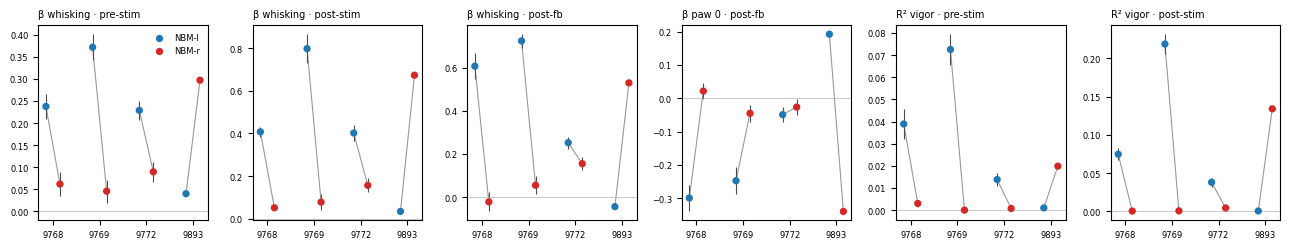

,between mice,between fibers of a mouse,ratio
metric,,,
β paw 0 · pre-stim,0.0023,0.0009,0.4191
β whisking · pre-stim,0.0007,0.0278,41.3945
β licking · pre-stim,0.0243,0.1779,7.3098
β paw 0 · post-stim,0.0014,0.0143,10.2847
β whisking · post-stim,0.0082,0.1389,16.8833
β licking · post-stim,0.0187,0.1309,7.0073
β paw 0 · post-fb,0.0027,0.0533,19.4912
β whisking · post-fb,0.0065,0.1478,22.9058
β licking · post-fb,0.0018,0.0083,4.5055


In [4]:
G, VAR = ci.fiber_vs_mouse(TAB[TAB.target_NM == 'NBM-ACh'], METRICS)
SHOW2 = ['β whisking · pre-stim', 'β whisking · post-stim', 'β whisking · post-fb', 'β paw 0 · post-fb',
         'R² vigor · pre-stim', 'R² vigor · post-stim']
fig, axes = plt.subplots(1, len(SHOW2), figsize=(13, 2.6))
for ax, m in zip(axes, SHOW2):
    fm = G.groupby(['subject', 'region'])[m].agg(['mean', 'sem']).reset_index()
    for k, (s, d) in enumerate(fm.groupby('subject')):
        d = d.sort_values('region')
        x = k + np.array([-0.15, 0.15])
        ax.plot(x, d['mean'], color='0.6', lw=0.8)
        ax.errorbar(x, d['mean'], d['sem'], fmt='none', ecolor='0.3', lw=0.8)
        ax.scatter(x, d['mean'], c=['C0', 'C3'], s=18, zorder=3)
    ax.set_xticks(range(G['subject'].nunique()), [s[-4:] for s in sorted(G['subject'].unique())], fontsize=6)
    ax.axhline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6); ax.set_title(m, fontsize=7, loc='left')
axes[0].scatter([], [], c='C0', s=18, label='NBM-l'); axes[0].scatter([], [], c='C3', s=18, label='NBM-r')
axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()
VAR.assign(ratio=VAR['between fibers of a mouse'] / VAR['between mice']).set_index('metric').round(4)

**Reading.** Coupling is very stable from session to session (ICC up to .76 for DR-5HT, split-half > .9), and neither recording day nor signal quality explains it. But in the bilateral NBM mice, the two fibers of one mouse differ far more than mice do (left strong / right weak in three mice, the reverse in the fourth). So the stable quantity is the **fiber**, likely its placement or expression, not the animal. With one fiber per mouse elsewhere, "mouse trait" and "fiber placement" are confounded. Next: placement coordinates (histology) per fiber, to test whether coupling maps onto location.